Epoch 1/5
687/687 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.3424 - loss: 2.1721 - val_accuracy: 0.5620 - val_loss: 1.3999
Epoch 2/5
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6120 - loss: 1.2173 - val_accuracy: 0.6811 - val_loss: 0.9784
Epoch 3/5
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7281 - loss: 0.8512 - val_accuracy: 0.7815 - val_loss: 0.7206
Epoch 4/5
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7966 - loss: 0.6407 - val_accuracy: 0.8188 - val_loss: 0.5325
Epoch 5/5
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8523 - loss: 0.4890 - val_accuracy: 0.8463 - val_loss: 0.4426
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6907 - loss: 1.0999
Test Accuracy: 69.0741777420044 %
Test Loss: 1.099872350692749


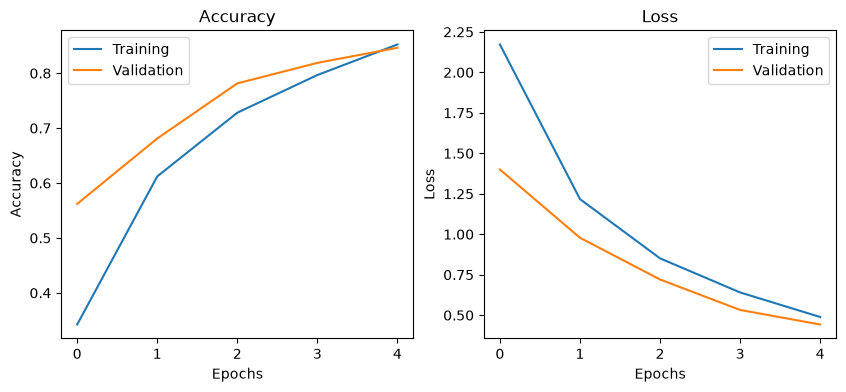

In [1]:

# 1. Import libraries
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# 2. Load dataset
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# 3. Separate images and labels
X_train = train.drop("label", axis=1).values
y_train = train["label"].values.copy()

X_test = test.drop("label", axis=1).values
y_test = test["label"].values.copy()

# Correct labels (J and Z are excluded)
y_train[y_train > 9] -= 1
y_test[y_test > 9] -= 1

# 4. Normalize images
X_train = X_train / 255.0
X_test = X_test / 255.0

# 5. Create FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(24, activation='softmax')
])

# 6. Compile model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 7. Train model
history = model.fit(X_train, y_train,
                    epochs=5,
                    batch_size=32,
                    validation_split=0.2)

# 8. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")
print("Test Loss:", loss)

# 9. Plot accuracy and loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])

plt.show()


# Practical 1E – Feedforward Neural Network (FNN) for Sign Language MNIST Classification



Difficulty: Medium

Deep Learning – ANN / FNN



Let's prepare this practical from absolute zero, including the special part about J and Z being excluded from Sign Language MNIST. This is the most important difference from your previous FNN practicals and is something your examiner may specifically ask.

## 1. First, understand what Sign Language MNIST is

Sign Language MNIST is a dataset containing images of hand gestures representing letters of the English alphabet using American Sign Language (ASL).

The objective of our practical is to train a neural network that can recognize a hand gesture and predict the corresponding letter.

For example:

[HGR-ViT: Hand Gesture Recognition with Vision Transformer](https://images.openai.com/static-rsc-4/ED9zYFugXviR9k-Jq9RAkXxIO0m0U1EcHS_43tC590LOqK_FAdWM6a6iUforPC6u6PfyvoyqbDrq4MsrWRFJRIZxiM-cphKkMxTfbUXzn5vYCVG7hxXm9oJJK_QUXxZ9bCRQh585sk-QTMQQGXdnRXjFwexltNyVYuOnW0eTFHw?purpose=inline)

A person shows a hand gesture, and our model tries to identify which letter it represents.

### Important facts about the dataset

| Property         | Value          |
| ---------------- | -------------- |
| Image dimensions | 28 × 28 pixels |
| Image type       | Grayscale      |
| Pixel values     | 0–255          |
| Input features   | 784            |
| Total classes    | 24             |
| Excluded letters | J and Z        |
| Model type       | FNN            |

### Why are J and Z excluded?

This is VERY IMPORTANT.

American Sign Language uses hand movements to represent the letters J and Z.

- J requires a movement of the hand.
- Z requires drawing a Z-like movement with the hand.

A static image cannot properly represent these movements.

Therefore, the Sign Language MNIST dataset excludes J and Z.

There are 26 letters in the English alphabet:

\\[ 26-2=24 \text{ classes} \\]

Remember: Sign Language MNIST has 24 classes, not 26.

## 2. Understand the difference between all three practicals

You have now studied MNIST, CIFAR-10 and Sign Language MNIST.

| Property       | 1A MNIST  | 1C CIFAR-10 | 1E Sign Language |
| -------------- | --------- | ----------- | ---------------- |
| Image size     | 28 × 28   | 32 × 32     | 28 × 28          |
| Image type     | Grayscale | RGB         | Grayscale        |
| Input features | 784       | 3072        | 784              |
| Classes        | 10        | 10          | 24               |
| Hidden layers  | 1         | 2           | 2                |
| Output neurons | 10        | 10          | 24               |
| Optimizer      | SGD       | Adam        | Adam             |

The basic FNN working is the same. Only the dataset, input dimensions, output classes and some architecture choices change.

## 3. Overall working of this practical

Sign Language MNIST CSV

Training and testing images

Separate Images and Labels

X = Images, Y = Letters

Correct Labels

Adjust labels because J and Z are excluded

Normalize Images

Divide pixels by 255

FNN Architecture

784 → 128 → 64 → 24

Train using Adam

5 epochs, batch size 32

Evaluate and Plot

Accuracy and loss graphs

## 4. Complete code explanation – Line by line

### Step 1: Import libraries

```
import pandas as pdimport tensorflow as tfimport matplotlib.pyplot as plt
```

We import three libraries.

| Library    | Purpose                        |
| ---------- | ------------------------------ |
| Pandas     | Load CSV files                 |
| TensorFlow | Build and train neural network |
| Matplotlib | Plot accuracy and loss graphs  |

These are the same libraries you used in Practical 1A.

### Step 2: Load the dataset

```
train = pd.read_csv("sign_mnist_train.csv")test = pd.read_csv("sign_mnist_test.csv")
```

Here, we load two CSV files.

- `sign_mnist_train.csv` contains training images.
- `sign_mnist_test.csv` contains testing images.

Each CSV contains:

- One `label` column.
- 784 pixel columns.

Why 784?

Because the image size is 28 × 28.

\\[ 28 \times 28=784 \\]

### Step 3: Separate images and labels

```
X_train = train.drop("label", axis=1).valuesy_train = train["label"].values.copy()X_test = test.drop("label", axis=1).valuesy_test = test["label"].values.copy()
```

We separate the input and output data.

X_train and X_test

Contain the pixel values of hand gesture images.

y_train and y_test

Contain the actual labels representing the hand gestures.

For example:

```
y_train = [0, 1, 2, 3, 4, 5]
```

Each number represents a particular letter class.

Important: What is `.copy()`?

```
y_train = train["label"].values.copy()
```

`.copy()` creates an independent copy of the array.

Why do we use it?

Because we are going to modify the label values in the next step.

Without copying, the array may be read-only or may share data with the original Pandas data.

You previously encountered a read-only array error in this practical. This `.copy()` helps avoid that problem.

### Step 4: Correct labels – Most important concept

Your code:

```
# Correct labels (J and Z are excluded)y_train[y_train > 9] -= 1y_test[y_test > 9] -= 1
```

Most important viva question

Let's understand why we need this.

In Sign Language MNIST, the original labels are based on the alphabet positions.

| Letter | Original label |
| ------ | -------------- |
| A      | 0              |
| B      | 1              |
| C      | 2              |
| D      | 3              |
| E      | 4              |
| F      | 5              |
| G      | 6              |
| H      | 7              |
| I      | 8              |
| K      | 10             |
| L      | 11             |
| M      | 12             |
| N      | 13             |
| O      | 14             |
| P      | 15             |
| Q      | 16             |
| R      | 17             |
| S      | 18             |
| T      | 19             |
| U      | 20             |
| V      | 21             |
| W      | 22             |
| X      | 23             |
| Y      | 24             |

Notice something?

Labels 9 and 25 are missing.

Why?

Because:

- J = 9
- Z = 25

These letters are excluded.

But here is the problem:

Our neural network has 24 output neurons.

It expects class labels from 0 to 23.

But our original dataset contains labels such as 10, 11, 12, ..., 24.

We must shift the labels after 9 down by one.

That's why we write:

```
y_train[y_train > 9] -= 1
```

Let's understand this line in parts.

- `y_train > 9` checks which labels are greater than 9.
- `-=` means subtract and assign.
- `1` is subtracted from every label greater than 9.

Example:

| Original label | New label |
| -------------- | --------- |
| 0              | 0         |
| 5              | 5         |
| 8              | 8         |
| 10             | 9         |
| 11             | 10        |
| 12             | 11        |
| 20             | 19        |
| 24             | 23        |

So now all labels are between 0 and 23.

We do the same for testing labels:

```
y_test[y_test > 9] -= 1
```

Why do we use the same correction for testing data?

Because both training and testing labels must follow the same class numbering.

Otherwise, the model's predictions and the actual testing labels would not match.

### Visual understanding of label correction

Before correction

0

1

2

3

4

5

6

7

8

10

11

12

...

24

Subtract 1 from labels greater than 9

After correction

0

1

2

3

4

5

6

7

8

9

10

11

12

13

14

15

16

17

18

19

20

21

22

23

All 24 classes now have continuous labels from 0 to 23.

Very important viva questions:

Q1. Why are J and Z excluded from Sign Language MNIST?

Because these two letters require hand movement, and a static image cannot represent their complete gestures.

Q2. Why do we have 24 output neurons?

Because there are 26 English alphabet letters, but J and Z are excluded.

Q3. Why do we subtract 1 from labels greater than 9?

To convert the original alphabet-based labels into continuous class labels from 0 to 23.

Q4. What does `y_train > 9` mean?

It checks which label values are greater than 9.

Q5. What does `-=` mean?

It is a subtraction assignment operator. For example, `x -= 1` means `x = x - 1`.

Q6. Why do we use `.copy()`?

To create a separate writable array so that we can modify the labels without encountering a read-only array error.

### Step 5: Normalize images

Your code:

```
X_train = X_train / 255.0X_test = X_test / 255.0
```

Here we normalize the image pixel values.

Original pixel values range from 0 to 255.

After dividing by 255, values range from 0 to 1.

Example:

| Original | Normalized |
| -------- | ---------- |
| 0        | 0.0        |
| 100      | 0.392      |
| 150      | 0.588      |
| 255      | 1.0        |

Why do we normalize?

It makes the input values smaller and helps the neural network train more efficiently.

We normalize both training and testing data so that they have the same scale.

### Step 6: Create the FNN model

Your code:

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(784,)),    tf.keras.layers.Dense(128, activation='relu'),    tf.keras.layers.Dense(64, activation='relu'),    tf.keras.layers.Dense(24, activation='softmax')])
```

This is where we define the neural network architecture.

Let's understand the architecture:

## Sign Language FNN Architecture

Input Layer

# 784

28 × 28 image pixels

Hidden Layer 1

# 128

Neurons – ReLU

Hidden Layer 2

# 64

Neurons – ReLU

Output Layer

# 24

Neurons – Softmax

Predicted Letter

A–I or K–Y

Let's understand each layer.

1\. Input layer

```
tf.keras.layers.Input(shape=(784,))
```

Our image is 28 × 28 pixels.

\\[ 28 \times 28=784 \\]

Therefore, the input layer accepts 784 features.

2\. First hidden layer

```
tf.keras.layers.Dense(128, activation='relu')
```

- Dense means fully connected layer.
- 128 means 128 neurons.
- ReLU is the activation function.

This layer learns patterns from hand gesture images.

3\. Second hidden layer

```
tf.keras.layers.Dense(64, activation='relu')
```

This layer has 64 neurons.

It helps the model learn more complex patterns from the previous layer.

4\. Output layer

```
tf.keras.layers.Dense(24, activation='softmax')
```

This is our final classification layer.

Why 24 neurons?

Because we have 24 possible letters.

Each neuron represents one letter class.

Softmax converts the output values into probabilities.

For example:

| Class         | Probability             |
| ------------- | ----------------------- |
| A             | 0.01                    |
| B             | 0.02                    |
| C             | 0.80                    |
| D             | 0.03                    |
| Other letters | Remaining probabilities |

The highest probability is for C, so the model predicts letter C.

Viva questions:

Q7. Why do we use 784 input neurons?

Because our image contains 28 × 28 = 784 pixels.

Q8. Why do we use 24 output neurons?

Because the dataset contains 24 letter classes.

Q9. Why do we use ReLU?

To introduce non-linearity and help the network learn complex patterns.

Q10. Why do we use Softmax?

To convert the output values into probabilities for the 24 classes.

### Step 7: Compile the model

Your code:

```
model.compile(optimizer='adam',              loss='sparse_categorical_crossentropy',              metrics=['accuracy'])
```

Here we configure the model before training.

There are three important parameters.

1\. Optimizer

```
optimizer='adam'
```

Adam stands for Adaptive Moment Estimation.

It is used to update the weights of the neural network to reduce the loss.

Your practical statement allows SGD or Adam, and your code uses Adam.

2\. Loss function

```
loss='sparse_categorical_crossentropy'
```

This calculates how far the model's predicted output is from the correct output.

Why do we use sparse categorical crossentropy?

Because our labels are integer values from 0 to 23.

For example:

```
y_train = [0, 1, 2, 3, 4, 5]
```

We don't need to convert them into one-hot encoded arrays.

3\. Metrics

```
metrics=['accuracy']
```

This measures the percentage of correctly classified images.

Example:

If the model correctly identifies 900 out of 1,000 images:

\\[ Accuracy=\frac{900}{1000}\times100=90\\% \\]

Viva questions:

Q11. What is Adam?

Adam is an optimization algorithm that automatically adapts the learning rate while updating neural network weights.

Q12. What is loss?

Loss measures the error between actual and predicted outputs.

Q13. What is accuracy?

Accuracy measures the percentage of correct predictions.

Q14. Why do we use sparse categorical crossentropy?

Because our dataset has multiple classes, and labels are represented as integers.

### Step 8: Train the model

Your code:

```
history = model.fit(X_train, y_train,                    epochs=5,                    batch_size=32,                    validation_split=0.2)
```

This is where the model learns from the training images.

Let's understand the parameters.

| Parameter              | Meaning                                     |
| ---------------------- | ------------------------------------------- |
| `X_train`              | Training images                             |
| `y_train`              | Correct training labels                     |
| `epochs=5`             | Train for 5 complete passes                 |
| `batch_size=32`        | Process 32 images per batch                 |
| `validation_split=0.2` | Reserve 20% of training data for validation |

What is an epoch?

One complete pass through the entire training dataset.

Here, we train the model for 5 epochs.

What is batch size?

The number of images processed together before updating the model weights.

Here, 32 images are processed in one batch.

What is validation split?

It reserves 20% of the training data to monitor model performance during training.

What is history?

It stores training and validation loss and accuracy for each epoch.

Viva questions:

Q15. How many epochs are used?

5 epochs.

Q16. What is batch size?

Q17. Why do we use validation data?

To monitor model performance during training and identify possible overfitting.

Q18. What is backpropagation?

It calculates gradients of the loss and passes them backward through the network so that the optimizer can update weights.

### Step 9: Evaluate the model

Your code:

```
loss, accuracy = model.evaluate(X_test, y_test)print("Test Accuracy:", accuracy * 100, "%")print("Test Loss:", loss)
```

Here, we evaluate our trained model using testing images.

`model.evaluate()` returns:

1. Test loss.
2. Test accuracy.

For example:

```
Test Accuracy: 85.5 %
Test Loss: 0.45
```

These are example values only.

What is test accuracy?

It measures how many unseen testing images are classified correctly.

What is test loss?

It measures the prediction error on testing data.

Remember:

- Higher accuracy is generally better.
- Lower loss is generally better.

### Step 10: Plot training and validation graphs

Your code:

```
plt.figure(figsize=(10, 4))
```

This creates a figure with width 10 inches and height 4 inches.

What is figsize?

It controls the size of the graph.

Now:

```
plt.subplot(1, 2, 1)
```

This divides the figure into:

- 1 row.
- 2 columns.
- Selects the first position.

We use two graphs side by side.

First graph – Accuracy

```
plt.plot(history.history['accuracy'])plt.plot(history.history['val_accuracy'])plt.title("Accuracy")plt.xlabel("Epochs")plt.ylabel("Accuracy")plt.legend(["Training", "Validation"])
```

Here:

- `accuracy` = Training accuracy.
- `val_accuracy` = Validation accuracy.
- `xlabel` = Horizontal axis represents epochs.
- `ylabel` = Vertical axis represents accuracy.
- `legend` = Identifies training and validation lines.

Second graph – Loss

```
plt.subplot(1, 2, 2)plt.plot(history.history['loss'])plt.plot(history.history['val_loss'])plt.title("Loss")plt.xlabel("Epochs")plt.ylabel("Loss")plt.legend(["Training", "Validation"])plt.show()
```

Here:

- `loss` = Training loss.
- `val_loss` = Validation loss.

`plt.show()` displays both graphs.

How to interpret these graphs?

[Frontiers | Lightweight deep learning system for automated bone age assessment in Chinese children: enhancing clinical efficiency and diagnostic accuracy](https://images.openai.com/static-rsc-4/W4hZZ5nwq6sy0b3AfGy1QFFsJTUSCfbeFGD1AWIH3XErgdBYVUuupmDcGHxPIBRggd-n78WtCQ28q32_ehPX-1KgrHJX4p3N0FIxYbePXPUPPJ0J8GHrI9WEF9qnWzbXSmOLLKI4clJ7_FZEvcyjrR5u4oqOeZnIHsCIfj80ouo?purpose=inline)

Accuracy graph

Generally increases as the model learns.

[A Practical Introduction to Keras Callbacks in TensorFlow 2 | by YeeJay | TDS Archive | Medium](https://images.openai.com/static-rsc-4/KZN7u0B1kXvVQIpx3WFoLdOOpHDDVRh9TwTJ2UH_PgOtvfz63GnYsxyJBFczGIEAKm-7KorWIU-DRfsPFcxOENaFPrg8OcN1fteZljoooywpdALyZtS7thUY4JooPtaNVaOhCnchlrEYla4b6foBzOGV_8EHvORZ6FZOldn1kjM?purpose=inline)

Loss graph

Generally decreases as the model learns.

Viva questions:

Q19. Why do we plot accuracy?

To observe how classification performance changes during training.

Q20. Why do we plot loss?

To observe how prediction error changes during training.

Q21. What does `val_accuracy` mean?

It is the accuracy calculated on validation data after each epoch.

Q22. What does `subplot(1,2,1)` mean?

It creates a layout of one row and two columns and selects the first graph position.

## 5. Most important additional viva questions

These questions cover concepts beyond your code.

| Question                                 | Answer                                                                                               |
| ---------------------------------------- | ---------------------------------------------------------------------------------------------------- |
| What is ASL?                             | American Sign Language.                                                                              |
| What is image classification?            | Assigning an image to a particular category.                                                         |
| What is supervised learning?             | Learning from labelled training examples.                                                            |
| What is grayscale?                       | An image made up of shades of black, white and grey.                                                 |
| What is a pixel?                         | The smallest unit of a digital image.                                                                |
| What is a neuron?                        | A processing unit of an artificial neural network.                                                   |
| What is a weight?                        | A learnable numerical value that controls connections between neurons.                               |
| What is bias?                            | An additional learnable value that helps adjust neuron output.                                       |
| What is a hyperparameter?                | A setting chosen before or during model configuration, such as epochs and batch size.                |
| What is overfitting?                     | When a model performs well on training data but poorly on unseen data.                               |
| What is an FNN?                          | A neural network in which information moves from input to output without cycles in the forward pass. |
| What is an optimizer?                    | An algorithm that updates weights to minimize loss.                                                  |
| What is inference?                       | Using a trained model to make predictions on new images.                                             |
| Can CNN be used for Sign Language MNIST? | Yes. CNN can learn spatial features from hand gesture images.                                        |

## 6. Important comparisons

### A. MNIST vs Sign Language MNIST

| MNIST                         | Sign Language MNIST      |
| ----------------------------- | ------------------------ |
| Recognizes handwritten digits | Recognizes hand gestures |
| 10 classes                    | 24 classes               |
| Output neurons = 10           | Output neurons = 24      |
| Labels 0–9                    | Corrected labels 0–23    |

### B. FNN vs CNN

| FNN                         | CNN                                           |
| --------------------------- | --------------------------------------------- |
| Uses fully connected layers | Uses convolution layers                       |
| Flattens images             | Processes image spatial structure             |
| Simple architecture         | Better for image feature extraction           |
| Can classify hand gestures  | Generally more suitable for image recognition |

### C. Training vs Validation vs Testing

| Training        | Validation             | Testing                  |
| --------------- | ---------------------- | ------------------------ |
| Learns patterns | Monitors performance   | Checks final performance |
| Updates weights | Doesn't update weights | Doesn't update weights   |
| `model.fit()`   | `validation_split`     | `model.evaluate()`       |

## 7. Ready-to-speak explanation for your examiner

If the examiner asks you to explain the practical, you can say this:

Practical explanation

"In this practical, I have implemented a Feedforward Neural Network using TensorFlow and Keras for Sign Language MNIST classification.

Sign Language MNIST is a dataset containing grayscale images of hand gestures representing English alphabet letters.

It contains 24 classes because the letters J and Z are excluded, as they require hand movement.

First, I imported the necessary libraries and loaded the training and testing CSV files.

Then, I separated the images and labels and corrected the labels by subtracting one from values greater than 9, so that all classes are numbered from 0 to 23.

After that, I normalized the pixel values by dividing them by 255.

I created an FNN using Keras Sequential with an input size of 784, two hidden layers containing 128 and 64 neurons using ReLU activation, and an output layer containing 24 neurons using Softmax activation.

I compiled the model using Adam optimizer, sparse categorical crossentropy loss and accuracy metrics.

Then, I trained the model for 5 epochs with a batch size of 32 and 20% validation data.

Finally, I evaluated the model on testing data and plotted training and validation accuracy and loss graphs."

&#x20;Copy explanation

## 8. Quick revision sheet – Learn these before viva

## Practical 1E – Important numbers

# 28 × 28

Image dimensions

# 784

Input features

# 128, 64

Hidden neurons

# 24

Output neurons

# 5

Epochs

# 32

Batch size

Important functions

- `pd.read_csv()` – Load CSV.
- `drop()` – Remove label column.
- `.copy()` – Create writable copy.
- `y_train > 9` – Find labels greater than 9.
- `-= 1` – Subtract one.
- `/255.0` – Normalize pixels.
- `Sequential()` – Create model.
- `Dense()` – Create fully connected layer.
- `compile()` – Configure model.
- `fit()` – Train model.
- `evaluate()` – Evaluate model.
- `subplot()` – Arrange multiple graphs.

## 9. Mock viva – Test yourself

Let's check whether you really understood the practical.

7 viva questions

0/7 answered

Q1. Why are J and Z excluded from Sign Language MNIST?

They are difficult to pronounce

They require hand movement

They are not English letters

Q2. Why do we use 24 output neurons?

There are 24 pixels

There are 24 hidden layers

There are 24 gesture classes

Q3. What does y_train[y_train > 9] -= 1 do?

Increases all labels by 1

Decreases labels greater than 9 by 1

Removes all labels greater than 9

Q4. Why do we use .copy() for labels?

To make a separate writable array

To normalize images

To create a neural network

Q5. What is the input shape of our model?

(28, 28)

(3072,)

(784,)

Q6. Which optimizer is used?

Adam

ReLU

Softmax

Q7. What does validation_split=0.2 mean?

20% of testing data

20% of training data for validation

20 epochs

Submit answers

My advice for this practical: Give extra attention to the label correction:

```
y_train[y_train > 9] -= 1y_test[y_test > 9] -= 1
```

This is the special part of Practical 1E. If you can explain why J and Z are excluded, why 24 output neurons are used, and how labels are corrected, you'll be well prepared for the most important questions.

One final concept to remember: Practical 1A, 1C and 1E all use FNN. Once you understand the basic FNN architecture, you mainly need to understand what changes in the dataset, input shape and number of output classes.